In [1]:
import pandas as pd
import numpy as np

print("Required libraries imported successfully!")

Required libraries imported successfully!


In [2]:
df = pd.read_csv(
    "datasets_435_896_sales_data_sample.csv",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 2823
Columns: 25


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
# PHASE 1: DATA UNDERSTANDING

print("===== DATA PROFILING REPORT =====")

# 1. Dataset information
print("\n1. Dataset Shape:")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# 2. Column names
print("\n2. Column Names:")
print(df.columns.tolist())

# 3. Missing values
print("\n3. Missing Values:")
print(df.isnull().sum())

# 4. Duplicate records
print("\n4. Duplicate Records:")
print(df.duplicated().sum())

# 5. Data types
print("\n5. Data Types:")
print(df.dtypes)

# 6. Unique countries
print("\n6. Unique Countries:")
print(df["COUNTRY"].nunique())
print(df["COUNTRY"].unique())

# 7. Unique territories
print("\n7. Unique Territories:")
print(df["TERRITORY"].nunique())
print(df["TERRITORY"].unique())

# 8. Product categories
print("\n8. Product Categories:")
print(df["PRODUCTLINE"].unique())

# 9. Sales date range
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

print("\n9. Sales Date Range:")
print("Start Date:", df["ORDERDATE"].min())
print("End Date:", df["ORDERDATE"].max())

print("\n===== PROFILING COMPLETED =====")

===== DATA PROFILING REPORT =====

1. Dataset Shape:
Total Rows: 2823
Total Columns: 25

2. Column Names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

3. Missing Values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY       

In [4]:
print("===== DATA QUALITY SUMMARY =====")

print("Total Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("\nUnique Countries:",
      df["COUNTRY"].nunique())

print(df["COUNTRY"].unique())

print("\nUnique Territories:",
      df["TERRITORY"].nunique())

print(df["TERRITORY"].unique())

print("\nProduct Categories:")
print(df["PRODUCTLINE"].unique())

print("\nColumn Data Types:")
print(df.dtypes.to_string())

print("\n===== REPORT COMPLETED =====")

===== DATA QUALITY SUMMARY =====
Total Missing Values: 5157
Duplicate Rows: 0

Unique Countries: 19
<StringArray>
[        'USA',      'France',      'Norway',   'Australia',     'Finland',
     'Austria',          'UK',       'Spain',      'Sweden',   'Singapore',
      'Canada',       'Japan',       'Italy',     'Denmark',     'Belgium',
 'Philippines',     'Germany', 'Switzerland',     'Ireland']
Length: 19, dtype: str

Unique Territories: 3
<StringArray>
[nan, 'EMEA', 'APAC', 'Japan']
Length: 4, dtype: str

Product Categories:
<StringArray>
[     'Motorcycles',     'Classic Cars', 'Trucks and Buses',
     'Vintage Cars',           'Planes',            'Ships',
           'Trains']
Length: 7, dtype: str

Column Data Types:
ORDERNUMBER                  int64
QUANTITYORDERED              int64
PRICEEACH                  float64
ORDERLINENUMBER              int64
SALES                      float64
ORDERDATE           datetime64[us]
STATUS                         str
QTR_ID             

In [5]:
# PHASE 2: DATA CLEANING

# Create a separate copy
df_clean = df.copy()

# Missing values analysis
missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(by="Missing_Count", ascending=False)

print("===== MISSING VALUES REPORT =====")

display(missing_report)

print("Total Missing Values:",
      df_clean.isnull().sum().sum())

===== MISSING VALUES REPORT =====


,Missing_Count,Missing_Percentage
ADDRESSLINE2,2521,89.30
STATE,1486,52.64
TERRITORY,1074,38.04
POSTALCODE,76,2.69


Total Missing Values: 5157


In [6]:
# INVESTIGATE MISSING VALUES

print("===== STATE MISSING ANALYSIS =====")

state_missing = df_clean[
    df_clean["STATE"].isnull()
]

display(
    state_missing["COUNTRY"].value_counts()
)

print("\n===== TERRITORY MISSING ANALYSIS =====")

territory_missing = df_clean[
    df_clean["TERRITORY"].isnull()
]

display(
    territory_missing["COUNTRY"].value_counts()
)

print("\n===== POSTAL CODE MISSING ANALYSIS =====")

postal_missing = df_clean[
    df_clean["POSTALCODE"].isnull()
]

display(
    postal_missing["COUNTRY"].value_counts()
)

===== STATE MISSING ANALYSIS =====


COUNTRY
Spain          342
France         314
UK             118
Italy          113
Finland         92
Norway          85
Singapore       79
Denmark         63
Germany         62
Sweden          57
Austria         55
Belgium         33
Switzerland     31
Philippines     26
Ireland         16
Name: count, dtype: int64


===== TERRITORY MISSING ANALYSIS =====


COUNTRY
USA       1004
Canada      70
Name: count, dtype: int64


===== POSTAL CODE MISSING ANALYSIS =====


COUNTRY
USA    76
Name: count, dtype: int64

In [7]:
# PHASE 2: DATA CLEANING

# Create a separate working copy
df_clean = df.copy()

# 1. Remove extra spaces from text columns
text_cols = df_clean.select_dtypes(
    include=["object", "str"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# 2. Convert ORDERDATE to datetime
df_clean["ORDERDATE"] = pd.to_datetime(
    df_clean["ORDERDATE"],
    errors="coerce"
)

# 3. Convert numerical columns
numeric_cols = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "ORDERLINENUMBER",
    "SALES",
    "MSRP"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# 4. Check duplicate records
print("Duplicate records:",
      df_clean.duplicated().sum())

# 5. Check data types
print("\nData Types:")
print(df_clean.dtypes)

# 6. Check missing values again
print("\nMissing Values:")
display(
    df_clean.isnull().sum()[
        df_clean.isnull().sum() > 0
    ]
)

print("\nData cleaning validation completed!")

Duplicate records: 0

Data Types:
ORDERNUMBER                  int64
QUANTITYORDERED              int64
PRICEEACH                  float64
ORDERLINENUMBER              int64
SALES                      float64
ORDERDATE           datetime64[us]
STATUS                         str
QTR_ID                       int64
MONTH_ID                     int64
YEAR_ID                      int64
PRODUCTLINE                    str
MSRP                         int64
PRODUCTCODE                    str
CUSTOMERNAME                   str
PHONE                          str
ADDRESSLINE1                   str
ADDRESSLINE2                   str
CITY                           str
STATE                          str
POSTALCODE                     str
COUNTRY                        str
TERRITORY                      str
CONTACTLASTNAME                str
CONTACTFIRSTNAME               str
DEALSIZE                       str
dtype: object

Missing Values:


ADDRESSLINE2    2521
STATE           1486
POSTALCODE        76
TERRITORY       1074
dtype: int64


Data cleaning validation completed!


In [8]:
# PHASE 3: BUSINESS KPI CALCULATIONS

# 1. Total Sales
total_sales = df_clean["SALES"].sum()

# 2. Total Orders
total_orders = df_clean["ORDERNUMBER"].nunique()

# 3. Units Sold
units_sold = df_clean["QUANTITYORDERED"].sum()

# 4. Average Order Value
average_order_value = total_sales / total_orders

# Display KPI Dashboard
print("=" * 45)
print("       SALES PERFORMANCE DASHBOARD")
print("=" * 45)

print(f"Total Sales:        ${total_sales:,.2f}")
print(f"Total Orders:       {total_orders:,}")
print(f"Units Sold:         {units_sold:,}")
print(f"Average Order Value:${average_order_value:,.2f}")

print("=" * 45)

# Top 5 Product Lines
print("\nTOP 5 PRODUCT LINES BY SALES")

top_products = (
    df_clean.groupby("PRODUCTLINE")["SALES"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

display(top_products)

# Top 5 Countries
print("\nTOP 5 COUNTRIES BY SALES")

top_countries = (
    df_clean.groupby("COUNTRY")["SALES"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

display(top_countries)

# Top 10 Customers
print("\nTOP 10 CUSTOMERS BY SALES")

top_customers = (
    df_clean.groupby("CUSTOMERNAME")["SALES"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_customers)

       SALES PERFORMANCE DASHBOARD
Total Sales:        $10,032,628.85
Total Orders:       307
Units Sold:         99,067
Average Order Value:$32,679.57

TOP 5 PRODUCT LINES BY SALES


PRODUCTLINE
Classic Cars        3919615.66
Vintage Cars        1903150.84
Motorcycles         1166388.34
Trucks and Buses    1127789.84
Planes               975003.57
Name: SALES, dtype: float64


TOP 5 COUNTRIES BY SALES


COUNTRY
USA          3627982.83
Spain        1215686.92
France       1110916.52
Australia     630623.10
UK            478880.46
Name: SALES, dtype: float64


TOP 10 CUSTOMERS BY SALES


CUSTOMERNAME
Euro Shopping Channel           912294.11
Mini Gifts Distributors Ltd.    654858.06
Australian Collectors, Co.      200995.41
Muscle Machine Inc              197736.94
La Rochelle Gifts               180124.90
Dragon Souveniers, Ltd.         172989.68
Land of Toys Inc.               164069.44
The Sharp Gifts Warehouse       160010.27
AV Stores, Co.                  157807.81
Anna's Decorations, Ltd         153996.13
Name: SALES, dtype: float64

In [9]:
# PHASE 4: REGIONAL SALES ANALYSIS

# 1. Country-wise Revenue
country_sales = (
    df_clean.groupby("COUNTRY")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

print("===== COUNTRY-WISE REVENUE =====")
display(country_sales)

# 2. Territory-wise Revenue
territory_sales = (
    df_clean.assign(
        TERRITORY=df_clean["TERRITORY"].fillna("Unknown")
    )
    .groupby("TERRITORY")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

print("\n===== TERRITORY-WISE REVENUE =====")
display(territory_sales)

# 3. Country-wise Order Count
country_orders = (
    df_clean.groupby("COUNTRY")["ORDERNUMBER"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n===== COUNTRY-WISE ORDERS =====")
display(country_orders)

# 4. Top 5 Countries
print("\n===== TOP 5 COUNTRIES =====")
display(country_sales.head(5))

# 5. Revenue Contribution Percentage
country_contribution = (
    country_sales / country_sales.sum() * 100
).round(2)

print("\n===== COUNTRY REVENUE CONTRIBUTION =====")
display(country_contribution.sort_values(ascending=False))

===== COUNTRY-WISE REVENUE =====


COUNTRY
USA            3627982.83
Spain          1215686.92
France         1110916.52
Australia       630623.10
UK              478880.46
Italy           374674.31
Finland         329581.91
Norway          307463.70
Singapore       288488.41
Denmark         245637.15
Canada          224078.56
Germany         220472.09
Sweden          210014.21
Austria         202062.53
Japan           188167.81
Switzerland     117713.56
Belgium         108412.62
Philippines      94015.73
Ireland          57756.43
Name: SALES, dtype: float64


===== TERRITORY-WISE REVENUE =====


TERRITORY
EMEA       4979272.41
Unknown    3852061.39
APAC        746121.83
Japan       455173.22
Name: SALES, dtype: float64


===== COUNTRY-WISE ORDERS =====


COUNTRY
USA            112
France          37
Spain           36
Australia       19
UK              13
Norway           9
Finland          9
Singapore        9
Italy            8
Belgium          7
Austria          7
Denmark          7
Sweden           7
Germany          7
Canada           7
Japan            6
Philippines      3
Ireland          2
Switzerland      2
Name: ORDERNUMBER, dtype: int64


===== TOP 5 COUNTRIES =====


COUNTRY
USA          3627982.83
Spain        1215686.92
France       1110916.52
Australia     630623.10
UK            478880.46
Name: SALES, dtype: float64


===== COUNTRY REVENUE CONTRIBUTION =====


COUNTRY
USA            36.16
Spain          12.12
France         11.07
Australia       6.29
UK              4.77
Italy           3.73
Finland         3.29
Norway          3.06
Singapore       2.88
Denmark         2.45
Canada          2.23
Germany         2.20
Sweden          2.09
Austria         2.01
Japan           1.88
Switzerland     1.17
Belgium         1.08
Philippines     0.94
Ireland         0.58
Name: SALES, dtype: float64

In [10]:
# PHASE 5: PRODUCT AND TIME ANALYSIS

# 1. Product Line Revenue and Quantity
print("===== PRODUCT LINE ANALYSIS =====")

product_analysis = df_clean.groupby("PRODUCTLINE").agg(
    Total_Sales=("SALES", "sum"),
    Total_Quantity=("QUANTITYORDERED", "sum"),
    Total_Orders=("ORDERNUMBER", "nunique")
).sort_values(by="Total_Sales", ascending=False)

display(product_analysis.round(2))


# 2. Year-wise Sales Comparison
print("\n===== YEAR-WISE SALES =====")

yearly_sales = df_clean.groupby("YEAR_ID")["SALES"].sum()

display(yearly_sales)


# 3. Monthly Sales Trends
print("\n===== MONTHLY SALES =====")

monthly_sales = (
    df_clean.groupby(["YEAR_ID", "MONTH_ID"])["SALES"]
    .sum()
    .reset_index()
)

display(monthly_sales)


# 4. Quarterly Sales Performance
print("\n===== QUARTERLY SALES =====")

quarterly_sales = df_clean.groupby(
    ["YEAR_ID", "QTR_ID"]
)["SALES"].sum()

display(quarterly_sales)


# 5. Deal Size Distribution
print("\n===== DEAL SIZE DISTRIBUTION =====")

deal_analysis = df_clean.groupby("DEALSIZE").agg(
    Total_Orders=("ORDERNUMBER", "nunique"),
    Total_Sales=("SALES", "sum")
)

display(deal_analysis.round(2))


# 6. Highest and Lowest Performing Months
print("\n===== BEST AND WORST MONTH =====")

best_month = monthly_sales.loc[
    monthly_sales["SALES"].idxmax()
]

worst_month = monthly_sales.loc[
    monthly_sales["SALES"].idxmin()
]

print("Best Month:")
print(best_month)

print("\nLowest Month:")
print(worst_month)

===== PRODUCT LINE ANALYSIS =====


,Total_Sales,Total_Quantity,Total_Orders
PRODUCTLINE,,,
Classic Cars,3919615.66,33992,199
Vintage Cars,1903150.84,21069,175
Motorcycles,1166388.34,11663,72
Trucks and Buses,1127789.84,10777,73
Planes,975003.57,10727,59
Ships,714437.13,8127,65
Trains,226243.47,2712,45



===== YEAR-WISE SALES =====


YEAR_ID
2003    3516979.54
2004    4724162.60
2005    1791486.71
Name: SALES, dtype: float64


===== MONTHLY SALES =====


,YEAR_ID,MONTH_ID,SALES
0,2003,1,129753.60
1,2003,2,140836.19
2,2003,3,174504.90
3,2003,4,201609.55
4,2003,5,192673.11
5,2003,6,168082.56
6,2003,7,187731.88
7,2003,8,197809.30
8,2003,9,263973.36
9,2003,10,568290.97



===== QUARTERLY SALES =====


YEAR_ID  QTR_ID
2003     1          445094.69
         2          562365.22
         3          649514.54
         4         1860005.09
2004     1          833730.68
         2          766260.73
         3         1109396.27
         4         2014774.92
2005     1         1071992.36
         2          719494.35
Name: SALES, dtype: float64


===== DEAL SIZE DISTRIBUTION =====


,Total_Orders,Total_Sales
DEALSIZE,,
Large,119,1302119.26
Medium,292,6087432.24
Small,287,2643077.35



===== BEST AND WORST MONTH =====
Best Month:
YEAR_ID        2004.00
MONTH_ID         11.00
SALES       1089048.01
Name: 22, dtype: float64

Lowest Month:
YEAR_ID       2003.0
MONTH_ID         1.0
SALES       129753.6
Name: 0, dtype: float64


In [11]:
# Create Product Analysis Summary

product_analysis = df_clean.groupby("PRODUCTLINE").agg(
    Total_Sales=("SALES", "sum"),
    Total_Quantity=("QUANTITYORDERED", "sum"),
    Total_Orders=("ORDERNUMBER", "nunique")
)

display(product_analysis)

print("Product analysis created successfully!")

,Total_Sales,Total_Quantity,Total_Orders
PRODUCTLINE,,,
Classic Cars,3919615.66,33992,199
Motorcycles,1166388.34,11663,72
Planes,975003.57,10727,59
Ships,714437.13,8127,65
Trains,226243.47,2712,45
Trucks and Buses,1127789.84,10777,73
Vintage Cars,1903150.84,21069,175


Product analysis created successfully!


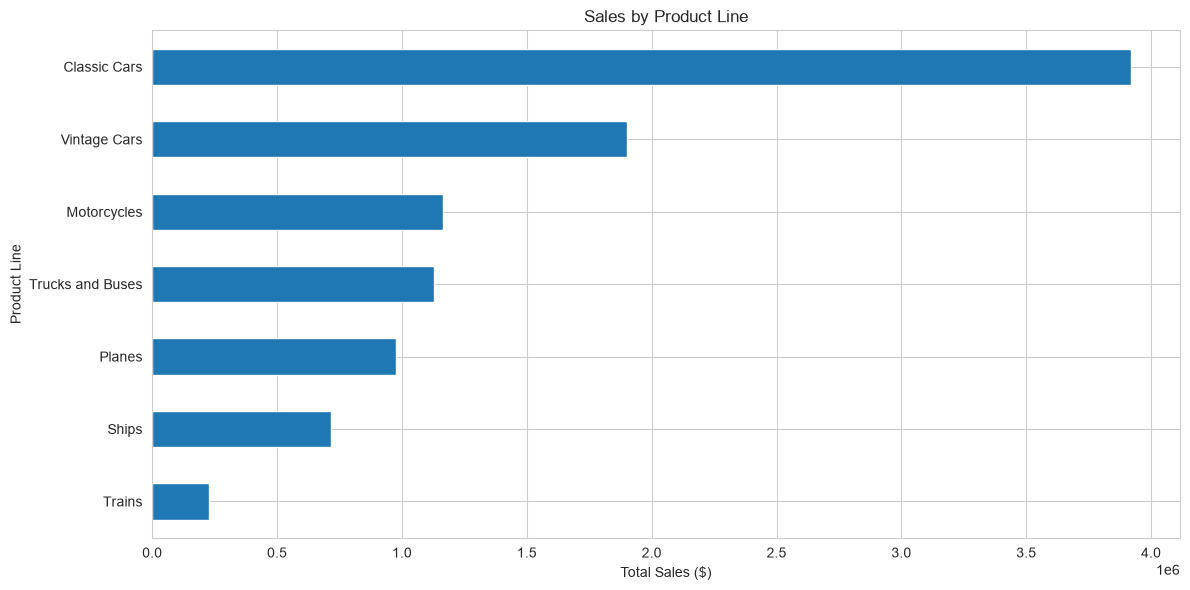

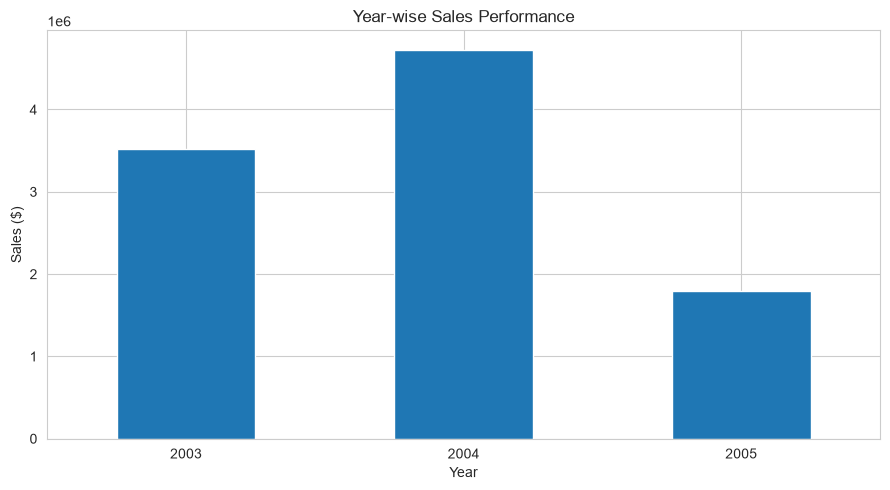

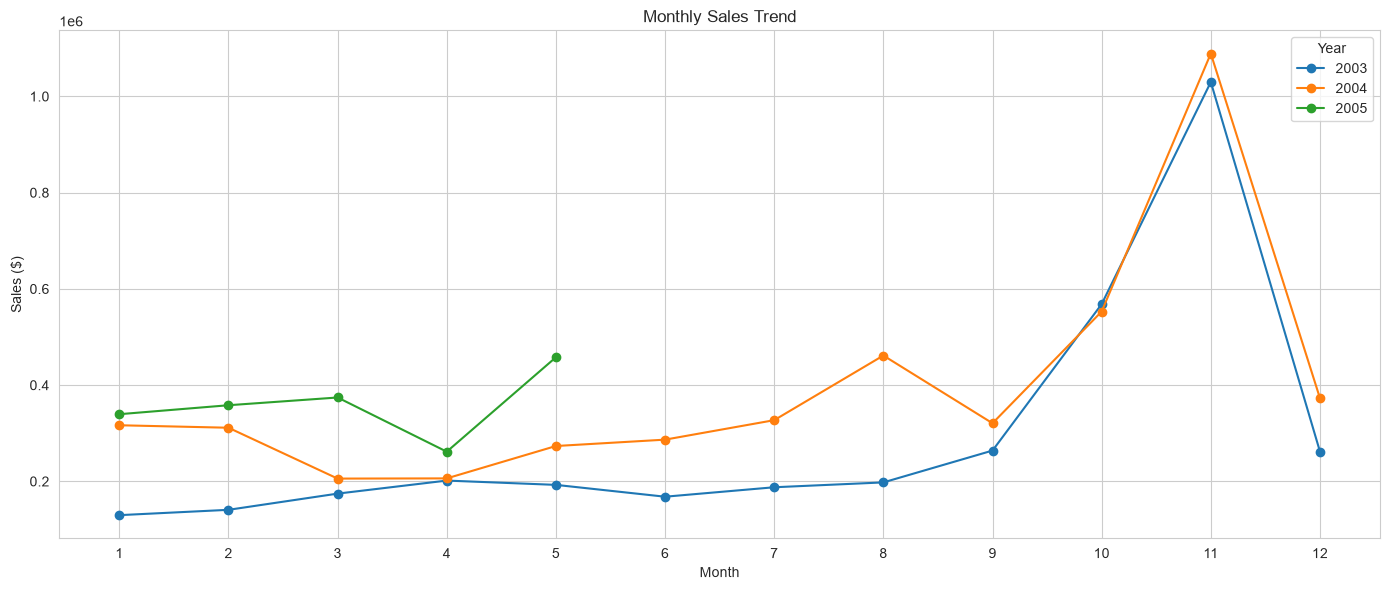

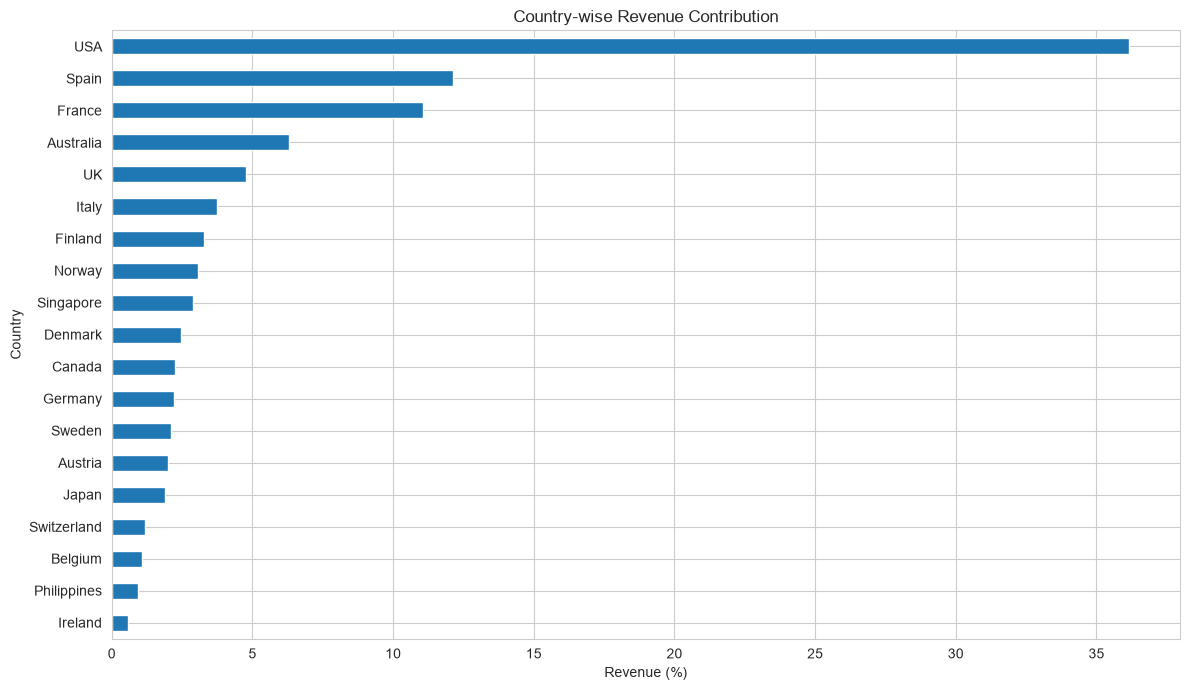

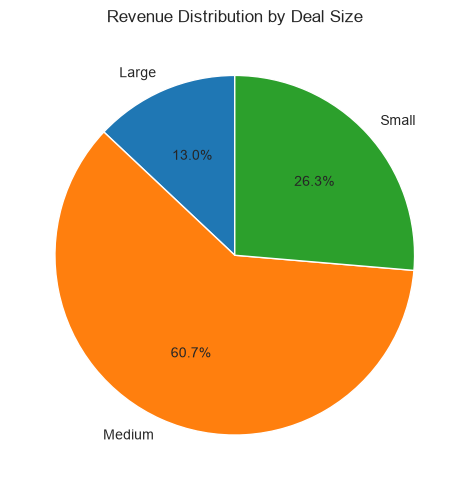

All Visualizations Generated Successfully!


In [12]:
# PHASE 6: DATA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# 1. Product Line Sales
plt.figure(figsize=(12, 6))

product_analysis["Total_Sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales by Product Line")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()


# 2. Year-wise Sales
plt.figure(figsize=(9, 5))

yearly_sales.plot(
    kind="bar"
)

plt.title("Year-wise Sales Performance")
plt.xlabel("Year")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 3. Monthly Sales Trend
plt.figure(figsize=(14, 6))

for year in monthly_sales["YEAR_ID"].unique():

    year_data = monthly_sales[
        monthly_sales["YEAR_ID"] == year
    ]

    plt.plot(
        year_data["MONTH_ID"],
        year_data["SALES"],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend(title="Year")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


# 4. Country-wise Revenue
plt.figure(figsize=(12, 7))

country_contribution.sort_values().plot(
    kind="barh"
)

plt.title("Country-wise Revenue Contribution")
plt.xlabel("Revenue (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# 5. Deal Size Distribution
plt.figure(figsize=(8, 5))

deal_analysis["Total_Sales"].plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Deal Size")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("All Visualizations Generated Successfully!")